# TP : Introduction au Deep Learning
## De la Régression Logistique aux Réseaux de Neurones avec Keras

**Durée estimée : 2 heures**

---

### Objectifs du TP

À la fin de ce TP, vous serez capables de :
1. Comprendre le lien entre la régression logistique et un réseau de neurones
2. Effectuer une **propagation avant (forward pass)** à la main
3. Concevoir l'architecture d'un réseau de neurones (couches, neurones, activations)
4. Construire, entraîner et évaluer un réseau de neurones avec **Keras**
5. Analyser l'impact des **hyperparamètres** sur les performances

---

### Plan du TP

| Partie | Contenu | Durée |
|--------|---------|-------|
| **Partie 1** | Rappels & Forward Pass à la main | ~25 min |
| **Partie 2** | Prise en main de Keras — Prédiction de maladie cardiaque | ~40 min |
| **Partie 3** | Expérimentation avec les hyperparamètres | ~30 min |
| **Partie 4** | Défi : Nouveau dataset, nouveau réseau | ~25 min |

---
## Installation des dépendances

Exécutez cette cellule **une seule fois** pour installer les bibliothèques nécessaires.

In [2]:
#%pip install --upgrade numpy scikit-learn tensorflow pandas matplotlib seaborn -q

⚠️ **Après l'installation, redémarrez le noyau (Kernel → Restart) puis exécutez les cellules à partir d'ici.**

---
## Imports et Configuration

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixer la graine pour la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

print(f"NumPy version : {np.__version__}")
print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version : {keras.__version__}")
print("\n✅ Toutes les bibliothèques sont chargées avec succès !")

NumPy version : 2.2.6
TensorFlow version : 2.21.0
Keras version : 3.12.1

✅ Toutes les bibliothèques sont chargées avec succès !


---
# Partie 1 : Rappels & Forward Pass à la Main (~25 min)

Avant de coder un réseau de neurones, il est essentiel de **comprendre ce qu'il fait** en interne.

## 1.1 — De la Régression Logistique au Neurone

Rappel : la régression logistique calcule :

$$P(y=1) = \sigma(z) = \frac{1}{1 + e^{-z}} \quad \text{où} \quad z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n$$

C'est exactement ce que fait **un seul neurone** avec une activation sigmoïde !

### Exercice 1.1 — Implémenter un neurone

Complétez les fonctions suivantes :

In [4]:
def sigmoid(z):
    """Fonction sigmoïde : σ(z) = 1 / (1 + e^(-z))"""
    # TODO : implémenter la fonction sigmoïde

    return 1 / (1 + np.exp(-z))

def relu(z):
    """Fonction ReLU : f(z) = max(0, z)"""
    # TODO : implémenter la fonction ReLU
    return np.maximum(0, z)

# --- Tests ---
print("=== Tests Sigmoïde ===")
print(f"sigmoid(0)   = {sigmoid(0):.4f}  (attendu : 0.5000)")
print(f"sigmoid(2)   = {sigmoid(2):.4f}  (attendu : 0.8808)")
print(f"sigmoid(-3)  = {sigmoid(-3):.4f}  (attendu : 0.0474)")

print("\n=== Tests ReLU ===")
print(f"relu(5)   = {relu(5)}   (attendu : 5)")
print(f"relu(-3)  = {relu(-3)}  (attendu : 0)")
print(f"relu(0)   = {relu(0)}   (attendu : 0)")

=== Tests Sigmoïde ===
sigmoid(0)   = 0.5000  (attendu : 0.5000)
sigmoid(2)   = 0.8808  (attendu : 0.8808)
sigmoid(-3)  = 0.0474  (attendu : 0.0474)

=== Tests ReLU ===
relu(5)   = 5   (attendu : 5)
relu(-3)  = 0  (attendu : 0)
relu(0)   = 0   (attendu : 0)


### Exercice 1.2 — Visualiser les fonctions d'activation

Tracez les trois fonctions d'activation vues en cours (Sigmoïde, ReLU, Linéaire) sur l'intervalle [-5, 5].

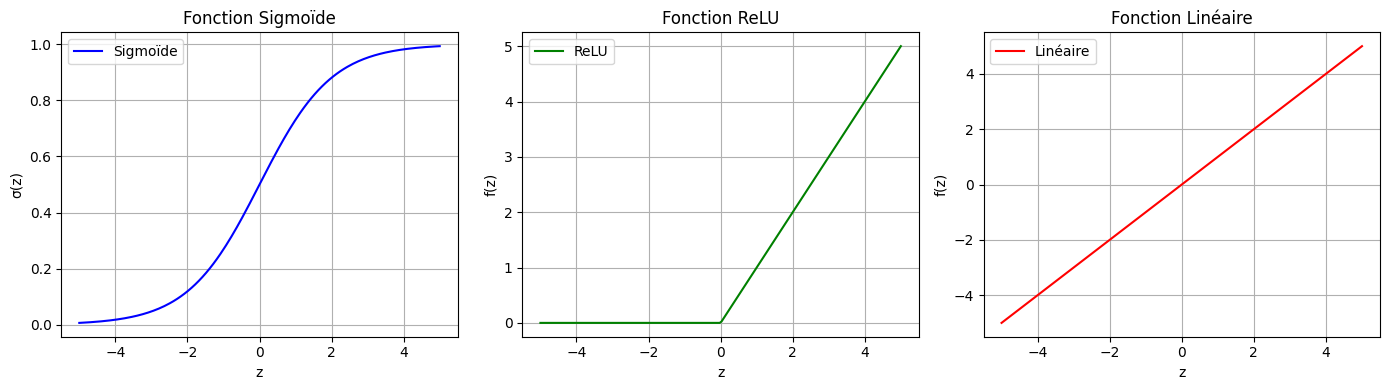

In [5]:
z = np.linspace(-5, 5, 200)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# TODO : Tracer les 3 fonctions d'activation
# axes[0] : Sigmoïde
axes[0].plot(z, sigmoid(z), label='Sigmoïde', color='blue')
axes[0].set_title('Fonction Sigmoïde')
axes[0].set_xlabel('z')
axes[0].set_ylabel('σ(z)')
axes[0].grid()
axes[0].legend()
# axes[1] : ReLU
axes[1].plot(z, relu(z), label='ReLU', color='green')
axes[1].set_title('Fonction ReLU')
axes[1].set_xlabel('z')
axes[1].set_ylabel('f(z)')
axes[1].grid()
axes[1].legend()

# axes[2] : Linéaire (f(z) = z)
axes[2].plot(z, z, label='Linéaire', color='red')
axes[2].set_title('Fonction Linéaire')
axes[2].set_xlabel('z')
axes[2].set_ylabel('f(z)')
axes[2].grid()
axes[2].legend()
# N'oubliez pas les titres, labels et grilles

plt.tight_layout()
plt.show()

In [6]:
"""
Notes:

for i in axes[1:]:
    axes[i].plot(z,)

"""

'\nNotes:\n\nfor i in axes[1:]:\n    axes[i].plot(z,)\n\n'

**Question :** Pourquoi utilise-t-on ReLU dans les couches cachées plutôt que la sigmoïde ? (Répondez en 1-2 phrases)

*Votre réponse :* ...
D’un point de vue mathématique, la sigmoïde a des dérivées qui deviennent très petites pour les grandes valeurs positives ou négatives, ce qui ralentit l’apprentissage à cause du vanishing gradient. En revanche, ReLU est simple à calculer : 
pour z>0, sa dérivée est constante (1), et pour z≤0, elle est 0, ce qui rend la propagation des gradients plus efficace et accélère l’apprentissage.

De plus, ReLU “filtre” les valeurs négatives : les neurones correspondants ne s’activent pas pour ces entrées, ce qui rend le réseau sparse (beaucoup de sorties nulles). Cette sparsité réduit les calculs inutiles et agit comme une régularisation implicite, aidant le réseau à mieux généraliser.

En résumé, ReLU permet d’apprendre plus rapidement, d’éviter le vanishing gradient, et de construire des réseaux plus efficaces et robustes grâce à la sparsité et à sa non-linéarité globale.

## 1.2 — Propagation Avant (Forward Pass) à la Main

Considérons le réseau vu en cours :
- **2 entrées** : $x_1$ (Moyenne/GPA), $x_2$ (Expérience)
- **1 couche cachée** : 3 neurones avec ReLU
- **1 sortie** : 1 neurone avec Sigmoïde

Les 13 paramètres (déjà entraînés) sont :

| Couche cachée | Poids | Biais |
|:---|:---|:---|
| Nœud 1 | w = [0.5, 0.1] | b = -0.3 |
| Nœud 2 | w = [-0.1, 0.3] | b = 0.2 |
| Nœud 3 | w = [0.2, -0.1] | b = 0.5 |

| Couche de sortie | Poids | Biais |
|:---|:---|:---|
| Nœud sortie | w = [-0.2, -0.3, -0.15] | b = 0.05 |

### Exercice 1.3 — Forward Pass pour un candidat

Candidat : $x_1 = 2.3$ (GPA), $x_2 = 10.2$ (années d'expérience)

Complétez le code pour effectuer la propagation avant :

In [7]:
# Entrées
x1, x2 = 2.3, 10.2

# === Étape 1 : Couche cachée ===
# Nœud 1 : z1 = b1 + w11*x1 + w12*x2, puis ReLU
z1 = -0.3 + 0.5 * x1 + 0.1 * x2
a1 = relu(z1)
print(f"Nœud 1 : z1 = {z1:.2f}, a1 = ReLU(z1) = {a1:.2f}")

# TODO : Nœud 2
z2 = 0.2 + -0.1 * x1 + 0.3 * x2
a2 = relu(z2)
print(f"Nœud 2 : z2 = {z2:.2f}, a2 = ReLU(z2) = {a2:.2f}")

# TODO : Nœud 3
z3 = 0.5 + 0.2 * x1 + -0.1 * x2
a3 = relu(z3)
print(f"Nœud 3 : z3 = {z3:.2f}, a3 = ReLU(z3) = {a3:.2f}")

# === Étape 2 : Couche de sortie ===
# TODO : z_out = biais + w1*a1 + w2*a2 + w3*a3
z_out = 0.05 + -0.2 * a1 + -0.3 * a2 + -0.15 * a3
y_hat = sigmoid(z_out)

print(f"\n--- Résultat ---")
print(f"z_out = {z_out:.3f}")
print(f"ŷ = σ(z_out) = {y_hat:.3f}")
print(f"\n→ Ce candidat a {y_hat*100:.1f}% de chance d'être convoqué en entretien")

Nœud 1 : z1 = 1.87, a1 = ReLU(z1) = 1.87
Nœud 2 : z2 = 3.03, a2 = ReLU(z2) = 3.03
Nœud 3 : z3 = -0.06, a3 = ReLU(z3) = 0.00

--- Résultat ---
z_out = -1.233
ŷ = σ(z_out) = 0.226

→ Ce candidat a 22.6% de chance d'être convoqué en entretien


### Exercice 1.4 — Forward Pass vectorisé (avec NumPy)

Refaites le même calcul mais en utilisant des **opérations matricielles** (comme le fait Keras en interne).

In [8]:
# Entrée (vecteur)
X = np.array([2.3, 10.2])

# Poids de la couche cachée (matrice 2x3)
W_hidden = np.array([
    [0.5, -0.1, 0.2],   # poids depuis x1
    [0.1,  0.3, -0.1]   # poids depuis x2
])
b_hidden = np.array([-0.3, 0.2, 0.5])

# TODO : Poids de la couche de sortie (vecteur 3x1)
W_output = np.array([-0.2,-0.3,-0.15])
b_output = 0.05

# === Forward Pass vectorisé ===
# TODO : Couche cachée
z_hidden = X @ W_hidden + b_hidden  # X @ W_hidden + b_hidden
a_hidden = np.maximum(0,z_hidden)  # appliquer ReLU (np.maximum)
print(f"Couche cachée (après ReLU) : {a_hidden}")

# TODO : Couche de sortie
z_output = a_hidden @ W_output + b_output  # a_hidden @ W_output + b_output
y_pred = sigmoid(z_output)
print(f"Sortie : ŷ = {y_pred:.3f}")

# Vérification : doit donner le même résultat que l'exercice précédent !

Couche cachée (après ReLU) : [1.87 3.03 0.  ]
Sortie : ŷ = 0.226


### Exercice 1.5 — Compter les paramètres

**Question :** Un réseau a 29 entrées, 1 couche cachée de 16 neurones (ReLU), et 1 sortie (Sigmoïde). Combien de paramètres a-t-il ?

Complétez le calcul :

In [9]:
n_inputs = 29
n_hidden = 16
n_output = 1

# TODO : Calculer le nombre de paramètres
poids_couche_cachee = n_inputs * n_hidden    # n_inputs × n_hidden
biais_couche_cachee = n_hidden     # un par neurone caché
poids_couche_sortie = n_hidden     # n_hidden × n_output
biais_couche_sortie = n_output     # un pour le neurone de sortie

total = poids_couche_cachee + biais_couche_cachee + poids_couche_sortie + biais_couche_sortie
print(f"Poids couche cachée : {poids_couche_cachee}")
print(f"Biais couche cachée : {biais_couche_cachee}")
print(f"Poids couche sortie : {poids_couche_sortie}")
print(f"Biais couche sortie : {biais_couche_sortie}")
print(f"\nTotal : {total} paramètres (attendu : 497)")

Poids couche cachée : 464
Biais couche cachée : 16
Poids couche sortie : 16
Biais couche sortie : 1

Total : 497 paramètres (attendu : 497)


---
# Partie 2 : Prédiction de Maladie Cardiaque avec Keras (~40 min)

Nous allons maintenant construire un **vrai** réseau de neurones pour prédire si un patient est atteint de maladie cardiaque, en utilisant le **Heart Disease UCI dataset** (Cleveland Clinic).

## 2.1 — Chargement et Exploration des Données

In [10]:
# Charger le dataset Heart Disease depuis UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

df = pd.read_csv(url, names=columns, na_values='?')
df.to_csv("processed_cleveland.csv", index=False)

df.dropna(inplace=True)

# Convertir la cible en binaire : 0 = pas de maladie, 1 = maladie
df['target'] = (df['target'] > 0).astype(int)

print(f"Dimensions du dataset : {df.shape}")
print(f"\nDistribution de la cible :")
print(df['target'].value_counts())
df.head()

Dimensions du dataset : (297, 14)

Distribution de la cible :
target
0    160
1    137
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Exercice 2.1 — Exploration rapide

Répondez aux questions suivantes en utilisant du code :

In [11]:
# TODO : Combien de patients au total ?
print(f"Nombre de patients :", df["target"].shape[0])

# TODO : Combien de variables indépendantes ?
print(f"Nombre de features :", df.shape[1])

# TODO : Quel est l'âge moyen des patients ?
print(f"Âge moyen :", df["age"].mean())

# TODO : Quel pourcentage de patients sont malades ?
print(f"Pourcentage de malades :", 100*df["target"].mean(),"%")

Nombre de patients : 297
Nombre de features : 14
Âge moyen : 54.54208754208754
Pourcentage de malades : 46.12794612794613 %


## 2.2 — Préparation des Données

Avant d'entraîner un réseau de neurones, il faut :
1. Séparer les features (X) de la cible (y)
2. Encoder les variables catégorielles (one-hot encoding)
3. Diviser en ensembles d'entraînement et de test
4. **Normaliser** les données (très important pour les réseaux de neurones !)

In [12]:
# Séparer X et y
X = df.drop('target', axis=1)
y = df['target']

# One-hot encoding des variables catégorielles
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print(f"Nombre de features après one-hot encoding : {X.shape[1]}")
print(f"Colonnes : {list(X.columns)}")

Nombre de features après one-hot encoding : 18
Colonnes : ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_1.0', 'restecg_2.0', 'slope_2.0', 'slope_3.0', 'thal_6.0', 'thal_7.0']


In [13]:
# TODO : Diviser en train/test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # TODO : compléter
    random_state=42,
    stratify=y            # maintenir la proportion de classes
)

print(f"Train : {X_train.shape[0]} patients")
print(f"Test  : {X_test.shape[0]} patients")

Train : 237 patients
Test  : 60 patients


In [14]:
# Normalisation (StandardScaler)
# IMPORTANT : on fit le scaler UNIQUEMENT sur les données d'entraînement !

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Moyenne avant normalisation (1ère feature) : {X_train.iloc[:, 0].mean():.2f}")
print(f"Moyenne après normalisation (1ère feature) : {X_train_scaled[:, 0].mean():.4f}")
print(f"Écart-type après normalisation : {X_train_scaled[:, 0].std():.4f}")

Moyenne avant normalisation (1ère feature) : 54.77
Moyenne après normalisation (1ère feature) : -0.0000
Écart-type après normalisation : 1.0000


**Question :** Pourquoi est-il important de normaliser les données avant d'entraîner un réseau de neurones ?


*Votre réponse :* ...
Si nous ne normalisons pas les données alors elles representeront les valeurs sous des echelles differentes, et auront ainsi des poids trop importants dans les combinaisons linéaires. Ce qui faussera totalement les résultats

## 2.3 — Construction du Réseau avec Keras

On va reproduire exactement le réseau vu en cours :
- **Entrée** : nombre de features (après one-hot encoding)
- **1 couche cachée** : 16 neurones, activation ReLU
- **Sortie** : 1 neurone, activation Sigmoïde

### Exercice 2.2 — Construire le modèle

In [15]:
n_features = X_train_scaled.shape[1]
print(f"Nombre de features en entrée : {n_features}")

# TODO : Construire le réseau avec l'API fonctionnelle de Keras
# Suivez les 4 étapes vues en cours :

# ① Couche d'entrée
inputs = keras.Input(shape=(n_features,))

# ② Couche cachée : Dense, 16 neurones, activation ReLU
h = keras.layers.Dense(16, activation='relu')(inputs)  # TODO : compléter avec keras.layers.Dense(...)

# ③ Couche de sortie : Dense, 1 neurone, activation Sigmoïde
outputs = keras.layers.Dense(1, activation='sigmoid')(h)  # TODO : compléter

# ④ Définir le modèle
model = keras.Model(inputs, outputs)

# Afficher le résumé
model.summary()

Nombre de features en entrée : 18


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

**Question :** Vérifiez le nombre de paramètres affiché par `model.summary()`. Correspond-il à votre calcul de l'exercice 1.5 ?

*Votre réponse :* ...
En 1.5 nous avions 29 entrées, plus généralement d'autres paramètres

## 2.4 — Compilation et Entraînement

Pour entraîner le modèle, il faut le **compiler** en spécifiant :
- La **fonction de perte** : Binary Cross-Entropy (classification binaire)
- L'**optimiseur** : Adam (variante du SGD)
- La **métrique** à suivre : Accuracy

### Exercice 2.3 — Compiler et entraîner le modèle

In [16]:
# TODO : Compiler le modèle
model.compile(
    optimizer='adam',   # TODO : 'adam'
    loss='binary_crossentropy',        # TODO : 'binary_crossentropy'
    metrics=['accuracy']      # TODO : ['accuracy']
)

In [17]:
# TODO : Entraîner le modèle
history = model.fit(
    X_train_scaled, 
    y_train,
    epochs=100,              # nombre d'itérations sur tout le dataset
    batch_size=16,           # cmb de données sont traitées a chaque maj
    validation_split=0.2,    # 20% des données de train pour la validation
    verbose=1                # afficher la progression
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.6402 - loss: 0.5932 - val_accuracy: 0.5833 - val_loss: 0.7102
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6772 - loss: 0.5583 - val_accuracy: 0.6042 - val_loss: 0.6886
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7037 - loss: 0.5287 - val_accuracy: 0.6250 - val_loss: 0.6701
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7143 - loss: 0.5031 - val_accuracy: 0.6458 - val_loss: 0.6543
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7407 - loss: 0.4808 - val_accuracy: 0.6458 - val_loss: 0.6412
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7672 - loss: 0.4611 - val_accuracy: 0.6458 - val_loss: 0.6303
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7989 - loss: 0.4436 - val_accuracy: 0.7292 - val_loss: 0.6209
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8254 - loss: 0.4278 - val_accuracy: 0.729

### Exercice 2.4 — Visualiser les courbes d'apprentissage

Tracez l'évolution de la **perte** et de l'**accuracy** au fil des epochs, pour l'entraînement et la validation.

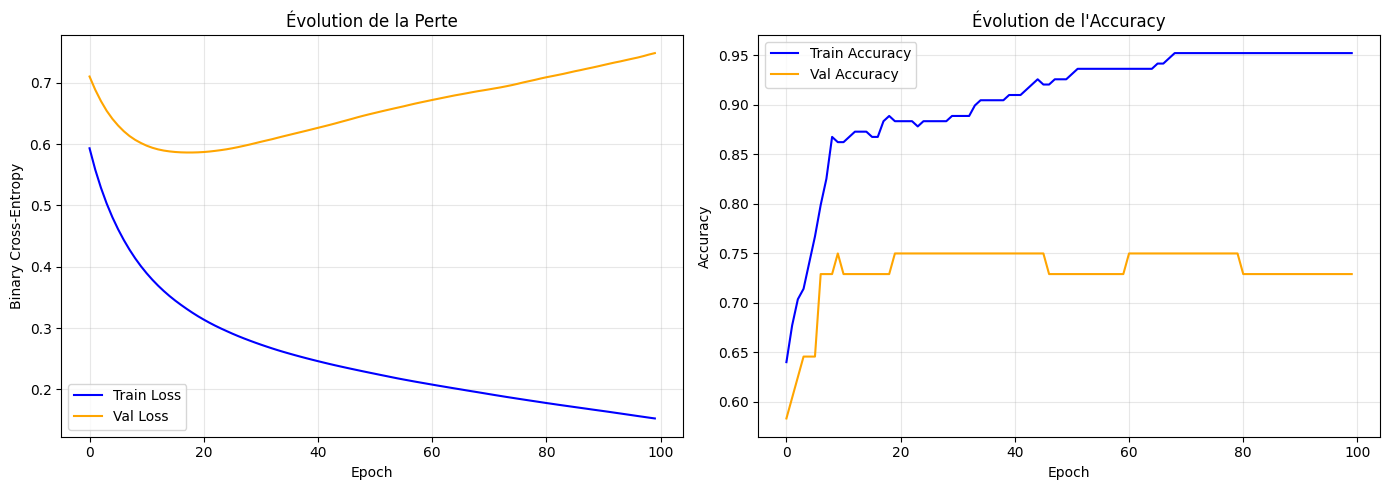

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Graphique 1 : Perte (Loss) ---
# TODO : Tracer history.history['loss'] et history.history['val_loss']
axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title('Évolution de la Perte')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Graphique 2 : Accuracy ---
# TODO : Tracer history.history['accuracy'] et history.history['val_accuracy']
axes[1].plot(history.history['accuracy'], label='Train Accuracy', color='blue')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
axes[1].set_title('Évolution de l\'Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Questions :**
1. La perte d'entraînement diminue-t-elle ? Et la perte de validation ?
2. Observez-vous des signes de **surapprentissage (overfitting)** ? Comment les repérer sur ces graphiques ?

*Vos réponses :* ...
1) La perte d'entrainement est strictement décroissante pour toutes epochs, alors que la validation est décroissante jusqu'à environ la 50eme epoch puis recrois.
2) L'overfitting se caracterise lorsque l'écart entre le train et la validation augmente plus spécifiquement lorsque la validation se dégrade et le train s'améliore. Ainsi nous pouvons observer sur les deux graphique vers 50 epochs

## 2.5 — Évaluation sur le Jeu de Test

### Exercice 2.5 — Prédictions et métriques

In [19]:
# Évaluer le modèle sur le jeu de test
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Perte sur le test  : {test_loss:.4f}")
print(f"Accuracy sur le test : {test_accuracy:.4f}")

Perte sur le test  : 0.3133
Accuracy sur le test : 0.8333


Matrice de confusion :
[[29  3]
 [ 7 21]]


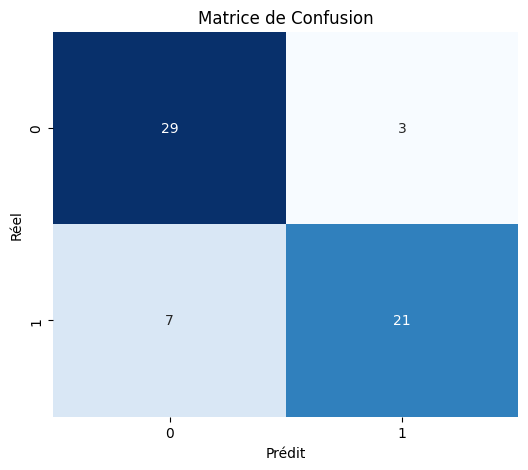

In [20]:
# Prédictions
y_pred_proba = model.predict(X_test_scaled, verbose=0).flatten()
y_pred = (y_pred_proba >= 0.5).astype(int)

# TODO : Afficher la matrice de confusion
# Utilisez confusion_matrix et sns.heatmap pour la visualiser
cm = confusion_matrix(y_test, y_pred)
print("Matrice de confusion :")
print(cm)

# TODO : Visualiser la matrice de confusion avec seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matrice de Confusion')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.show()

In [21]:
# Rapport de classification
print(classification_report(y_test, y_pred, target_names=['Sain', 'Malade']))

              precision    recall  f1-score   support

        Sain       0.81      0.91      0.85        32
      Malade       0.88      0.75      0.81        28

    accuracy                           0.83        60
   macro avg       0.84      0.83      0.83        60
weighted avg       0.84      0.83      0.83        60



---
# Partie 3 : Expérimentation avec les Hyperparamètres (~30 min)

L'objectif est de comprendre l'impact de chaque choix d'architecture sur les performances.

## 3.1 — Fonction utilitaire

Pour faciliter les expérimentations, créons une fonction qui construit, entraîne et évalue un modèle.

In [22]:
def build_and_train(hidden_layers, activation='relu', learning_rate=0.001, 
                    epochs=100, batch_size=16, verbose=0):
    """
    Construit, entraîne et évalue un réseau de neurones.
    
    Paramètres :
    -----------
    hidden_layers : list of int
        Nombre de neurones dans chaque couche cachée.
        Ex: [16] = 1 couche de 16, [32, 16] = 2 couches de 32 et 16
    activation : str
        Fonction d'activation pour les couches cachées
    learning_rate : float
        Taux d'apprentissage pour Adam
    epochs : int
        Nombre d'epochs
    batch_size : int
        Taille du minibatch
    
    Retourne :
    ---------
    model, history, test_accuracy
    """
    # Construction du modèle
    inputs = keras.Input(shape=(X_train_scaled.shape[1],))
    x = inputs
    for n_neurons in hidden_layers:
        x = layers.Dense(n_neurons, activation=activation)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs)
    
    # Compilation
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    # Entraînement
    history = model.fit(
        X_train_scaled, y_train,
        epochs=epochs, batch_size=batch_size,
        validation_split=0.2, verbose=verbose
    )
    
    # Évaluation
    _, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
    
    return model, history, test_acc

## 3.2 — Impact du nombre de neurones

### Exercice 3.1 — Comparer différentes tailles de couche cachée

Testez les architectures suivantes (1 seule couche cachée) :
- 4 neurones
- 16 neurones
- 64 neurones
- 128 neurones

In [23]:
neuron_configs = [4, 16, 64, 128]
results_neurons = {}

for n in neuron_configs:
    print(f"\n--- Entraînement avec {n} neurones ---")
    model_n, hist_n, acc_n = build_and_train([n], epochs=100)
    results_neurons[n] = {'history': hist_n, 'accuracy': acc_n}
    print(f"Accuracy test : {acc_n:.4f}")

# Résumé
print("\n=== Résumé ===")
for n, res in results_neurons.items():
    print(f"{n:>4} neurones → Accuracy test = {res['accuracy']:.4f}")


--- Entraînement avec 4 neurones ---
Accuracy test : 0.8000

--- Entraînement avec 16 neurones ---
Accuracy test : 0.8333

--- Entraînement avec 64 neurones ---
Accuracy test : 0.8167

--- Entraînement avec 128 neurones ---
Accuracy test : 0.8500

=== Résumé ===
   4 neurones → Accuracy test = 0.8000
  16 neurones → Accuracy test = 0.8333
  64 neurones → Accuracy test = 0.8167
 128 neurones → Accuracy test = 0.8500


**Question :** Plus de neurones = meilleur résultat ? Expliquez.

*Votre réponse :* ...
Pas nécessairement, car cela donne lieu a du surapprentissage, comme on peut l'observer, avec 16 neurones, les résultats de l'accuracy test sont meilleurs

## 3.3 — Impact de la profondeur (nombre de couches)

### Exercice 3.2 — Comparer la profondeur du réseau

Testez les architectures suivantes (avec 16 neurones par couche) :
- 1 couche : `[16]`
- 2 couches : `[16, 16]`
- 3 couches : `[16, 16, 16]`
- 5 couches : `[16, 16, 16, 16, 16]`

In [24]:
depth_configs = [
    [16],
    [16, 16],
    [16, 16, 16],
    [16, 16, 16, 16, 16]
]

results_depth = {}

for config in depth_configs:
    name = f"{len(config)} couches"
    print(f"\n--- {name} : {config} ---")
    # TODO : Entraîner et stocker les résultats
    model_d, hist_d, acc_d = build_and_train(config, epochs=100)
    results_depth[name] = {'history': hist_d, 'accuracy': acc_d}
    print(f"Accuracy test : {acc_d:.4f}")

# Résumé
print("\n=== Résumé ===")
for name, res in results_depth.items():
    print(f"{name:>12} → Accuracy test = {res['accuracy']:.4f}")


--- 1 couches : [16] ---
Accuracy test : 0.8000

--- 2 couches : [16, 16] ---
Accuracy test : 0.8333

--- 3 couches : [16, 16, 16] ---
Accuracy test : 0.8167

--- 5 couches : [16, 16, 16, 16, 16] ---
Accuracy test : 0.8500

=== Résumé ===
   1 couches → Accuracy test = 0.8000
   2 couches → Accuracy test = 0.8333
   3 couches → Accuracy test = 0.8167
   5 couches → Accuracy test = 0.8500


## 3.4 — Impact du Learning Rate

### Exercice 3.3 — Tester différents learning rates

Testez : 0.1, 0.01, 0.001, 0.0001


--- Learning Rate = 0.1 ---
Accuracy test : 0.8667

--- Learning Rate = 0.01 ---
Accuracy test : 0.8167

--- Learning Rate = 0.001 ---
Accuracy test : 0.8167

--- Learning Rate = 0.0001 ---
Accuracy test : 0.8333


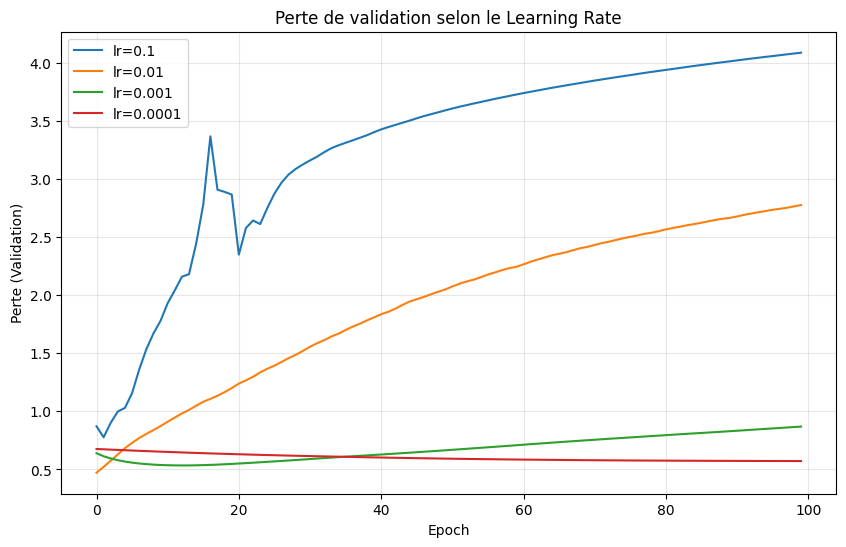

In [25]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
results_lr = {}

for lr in learning_rates:
    print(f"\n--- Learning Rate = {lr} ---")
    model_lr, hist_lr, acc_lr = build_and_train([16], learning_rate=lr, epochs=100)
    results_lr[lr] = {'history': hist_lr, 'accuracy': acc_lr}
    print(f"Accuracy test : {acc_lr:.4f}")

# TODO : Tracer les courbes de perte pour chaque learning rate sur le MÊME graphique
plt.figure(figsize=(10, 6))
for lr, res in results_lr.items():
    plt.plot(res['history'].history['val_loss'], label=f'lr={lr}')

plt.title('Perte de validation selon le Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Perte (Validation)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Questions :**
1. Quel learning rate donne les meilleurs résultats ?
2. Que se passe-t-il quand le learning rate est trop grand ? Trop petit ?

*Vos réponses :* ...
1) Dans notre cas, le learning rate aavec les meilleurs résultats est le 0.1.
2) Si le learning rate est trop grand, la validation peut avoir des oscillations ou des problemes de convergence.
S'il est trop petit, l'entrainement sera lent, et donc convergera lentement vers un minimum ou peut rester bloquer sur un minimum local.

## 3.5 — Synthèse des expérimentations

### Exercice 3.4 — Votre meilleur modèle

En vous basant sur vos expérimentations, construisez le meilleur modèle que vous pouvez. Justifiez vos choix.

In [28]:
# TODO : Construire votre meilleur modèle
# Choisissez l'architecture, le learning rate, le batch_size, les epochs

best_model, best_history, best_acc = build_and_train(
    hidden_layers=[16,16],   # TODO : choisir
    learning_rate=0.1,   # TODO : choisir
    epochs=100,          # TODO : choisir
    batch_size=16,      # TODO : choisir
    verbose=1
)

print(f"\n🏆 Accuracy de votre meilleur modèle : {best_acc:.4f}")

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7619 - loss: 0.5591 - val_accuracy: 0.6458 - val_loss: 0.9782
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8201 - loss: 0.3992 - val_accuracy: 0.7708 - val_loss: 0.7927
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8730 - loss: 0.2866 - val_accuracy: 0.7292 - val_loss: 0.8973
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9101 - loss: 0.2238 - val_accuracy: 0.7083 - val_loss: 1.4528
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9312 - loss: 0.1695 - val_accuracy: 0.6250 - val_loss: 2.2184
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9418 - loss: 0.1309 - val_accuracy: 0.6667 - val_loss: 2.6872
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9577 - loss: 0.1132 - val_accuracy: 0.6458 - val_loss: 3.2664
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9471 - loss: 0.1100 - val_accuracy: 0.66

**Justification de vos choix :**

*Votre réponse :* ...
En se basaant sur les réponses précédentes nous observons que 0.1 en learning rate donne le meilleur résultat, ainsi que deux couches de neurones. 

---
# Partie 4 : Défi — Nouveau Dataset (~25 min)

Appliquez tout ce que vous avez appris à un nouveau problème de classification binaire.

## Dataset : Breast Cancer Wisconsin

L'objectif est de prédire si une tumeur du sein est **maligne** ou **bénigne** à partir de 30 caractéristiques mesurées sur les cellules.

In [29]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X_bc = pd.DataFrame(data.data, columns=data.feature_names)
y_bc = data.target  # 0 = maligne, 1 = bénigne

print(f"Dataset : {X_bc.shape[0]} échantillons, {X_bc.shape[1]} features")
print(f"Classes : {dict(zip(data.target_names, np.bincount(y_bc)))}")
X_bc.head()

Dataset : 569 échantillons, 30 features
Classes : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Exercice 4.1 — Pipeline complet

Réalisez toutes les étapes du pipeline :

1. **Préparer** les données (train/test split, normalisation)
2. **Construire** un réseau de neurones adapté (justifiez vos choix)
3. **Entraîner** le modèle
4. **Évaluer** le modèle (accuracy, matrice de confusion, courbes d'apprentissage)
5. **Analyser** les résultats

In [30]:
# ======================================================
# ÉTAPE 1 : Préparation des données
# ======================================================
# TODO : Train/test split (80/20)
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc,
    test_size = 0.2,
    random_state=42,
    stratify=y_bc
)

# TODO : Normalisation (StandardScaler)

scaler_bc = StandardScaler() #on définit le scaler
X_train_bc_scaled = scaler_bc.fit_transform(X_train_bc) #on fit le scaler sur les données d'entraînement et on les transforme
X_test_bc_scaled = scaler_bc.transform(X_test_bc) #on transforme les données de test


In [31]:
# ======================================================
# ÉTAPE 2 : Construction du réseau
# ======================================================
# TODO : Définir l'architecture de votre réseau
# Justifiez vos choix !

inputs_bc = keras.Input(shape=(X_train_bc_scaled.shape[1],))

h1 = layers.Dense(16, activation='relu')(inputs_bc)
h2 = layers.Dense(16, activation='relu')(h1)

outputs_bc = layers.Dense(1, activation='sigmoid')(h2)

model_bc = keras.Model(inputs_bc, outputs_bc)
model_bc.summary()


Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# ======================================================
# ÉTAPE 3 : Compilation et entraînement
# ======================================================
# TODO : Compiler et entraîner
model_bc.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_bc = model_bc.fit(
    X_train_bc_scaled,
    y_train_bc,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)



Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8544 - loss: 0.4552 - val_accuracy: 0.9121 - val_loss: 0.4038
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9038 - loss: 0.3228 - val_accuracy: 0.9341 - val_loss: 0.2916
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9341 - loss: 0.2397 - val_accuracy: 0.9670 - val_loss: 0.2205
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9451 - loss: 0.1859 - val_accuracy: 0.9670 - val_loss: 0.1762
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9533 - loss: 0.1513 - val_accuracy: 0.9670 - val_loss: 0.1467
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9615 - loss: 0.1290 - val_accuracy: 0.9670 - val_loss: 0.1268
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9643 - loss: 0.1140 - val_accuracy: 0.9670 - val_loss: 0.1124
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9698 - loss: 0.1027 - val_accuracy: 0.9670 -

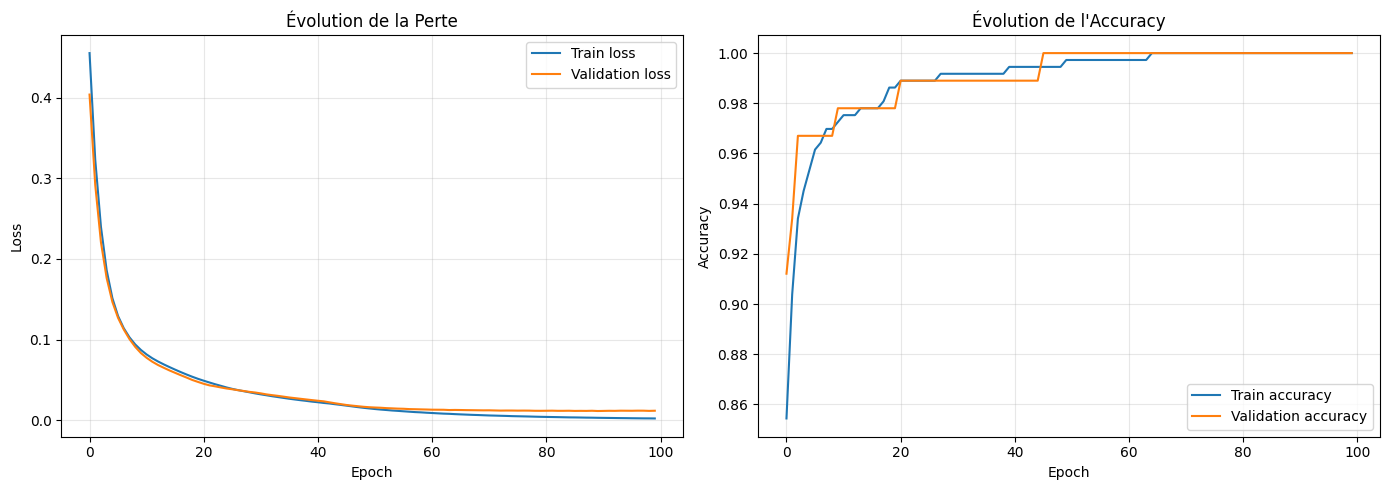

Perte sur le test : 0.1107
Accuracy sur le test : 0.9649
Matrice de confusion :
[[40  2]
 [ 2 70]]


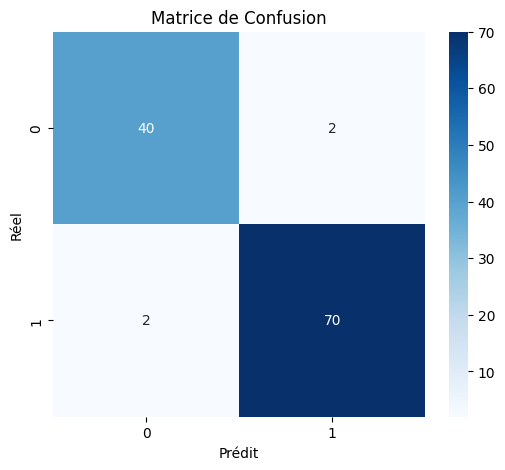

              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [33]:
# ======================================================
# ÉTAPE 4 : Évaluation
# ======================================================

# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_bc.history['loss'], label='Train loss')
axes[0].plot(history_bc.history['val_loss'], label='Validation loss')
axes[0].set_title("Évolution de la Perte")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_bc.history['accuracy'], label='Train accuracy')
axes[1].plot(history_bc.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title("Évolution de l'Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Évaluation sur le test
test_loss_bc, test_acc_bc = model_bc.evaluate(X_test_bc_scaled, y_test_bc, verbose=0)
print(f"Perte sur le test : {test_loss_bc:.4f}")
print(f"Accuracy sur le test : {test_acc_bc:.4f}")

# Matrice de confusion
y_pred_proba_bc = model_bc.predict(X_test_bc_scaled, verbose=0).flatten()
y_pred_bc = (y_pred_proba_bc >= 0.5).astype(int)

cm_bc = confusion_matrix(y_test_bc, y_pred_bc)
print("Matrice de confusion :")
print(cm_bc)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_bc, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de Confusion')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.show()

# Rapport de classification
print(classification_report(y_test_bc, y_pred_bc, target_names=data.target_names))

### Exercice 4.2 — Analyse

Répondez aux questions suivantes :

1. Quelle accuracy avez-vous obtenue sur le jeu de test ?
2. Dans le contexte médical, quelles erreurs sont les plus graves : les faux positifs ou les faux négatifs ? Pourquoi ?
3. Quel(le) métrique/indicateur devrait-on privilégier dans ce contexte : l'accuracy, la précision ou le rappel ?

*Vos réponses :*

1. Accuracy sur le test : 0.9649
2. Les faux négatifs, car on rate un malade
3. Il faut maximiser la métrics qui detecte les malades donc le rappel est a privilégier

---
## Bonus : Comparaison avec la Régression Logistique

Le réseau de neurones fait-il mieux que la simple régression logistique sur ce dataset ?

In [34]:
from sklearn.linear_model import LogisticRegression

# Entraîner une régression logistique sur les mêmes données
# Comparer l'accuracy avec votre réseau de neurones

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_bc_scaled, y_train_bc)
lr_accuracy = lr_model.score(X_test_bc_scaled, y_test_bc)

print(f"Régression logistique : {lr_accuracy:.4f}")
print(f"Réseau de neurones    : {test_acc_bc:.4f}")

Régression logistique : 0.9825
Réseau de neurones    : 0.9649


**Question Bonus :** Le réseau de neurones est-il toujours meilleur que la régression logistique ? Dans quelles situations un réseau de neurones est-il vraiment avantageux ?

*Votre réponse :* ...
Non les réseaux de neurones ne sont pas toujours meilleurs que la régression logistique. Ils sont a priorisés lorsque les données sont nombreuses.

---
## Résumé du TP

Dans ce TP, vous avez :

- ✅ Implémenté les fonctions d'activation (Sigmoïde, ReLU) **à la main**
- ✅ Effectué une **propagation avant** pas à pas, puis en version vectorisée
- ✅ Compté les **paramètres** d'un réseau de neurones
- ✅ Construit, entraîné et évalué un réseau avec **Keras**
- ✅ Expérimenté avec les **hyperparamètres** (neurones, couches, learning rate)
- ✅ Appliqué le pipeline complet à un **nouveau problème** de classification

### Points clés à retenir :

1. Un **neurone** = somme pondérée + fonction d'activation
2. Un **réseau de neurones** = empilement de couches de neurones pour apprendre des représentations
3. **Keras** rend la construction de réseaux très simple (4 lignes de code !)
4. Les **hyperparamètres** (architecture, learning rate, batch size) ont un impact majeur sur les performances
5. **Plus grand ≠ toujours meilleur** — attention à l'overfitting !